FIRST FIVE ROWS
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

DATASET SHAPE
(200, 5)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.1 KB
None

MISSING VAL

/lib/python3.13/site-packages/threadpoolctl.py:1932: UserWarning: Unable to import LDSO from pyodide_js._module. This should never happen.
  warnings.warn(


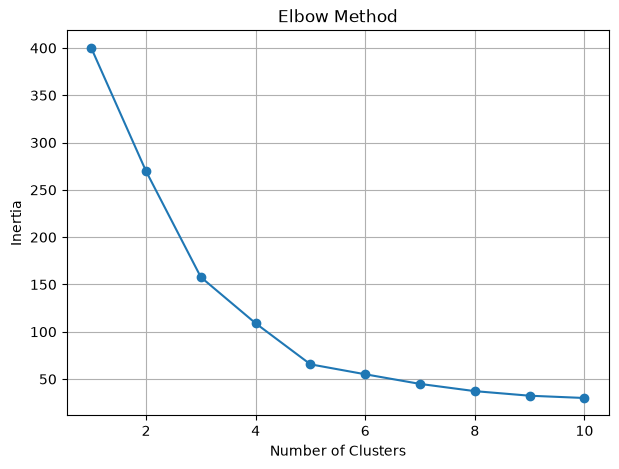


ALGORITHM: K-Means
Number of Clusters: 5
Silhouette Score: 0.5546571631111091
Davies-Bouldin Index: 0.5722356162263352


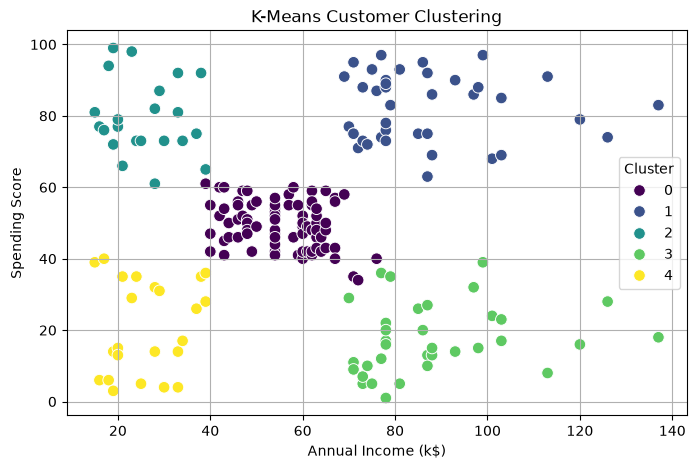


ALGORITHM: Agglomerative
Number of Clusters: 5
Silhouette Score: 0.5538089226688662
Davies-Bouldin Index: 0.5778621190740154


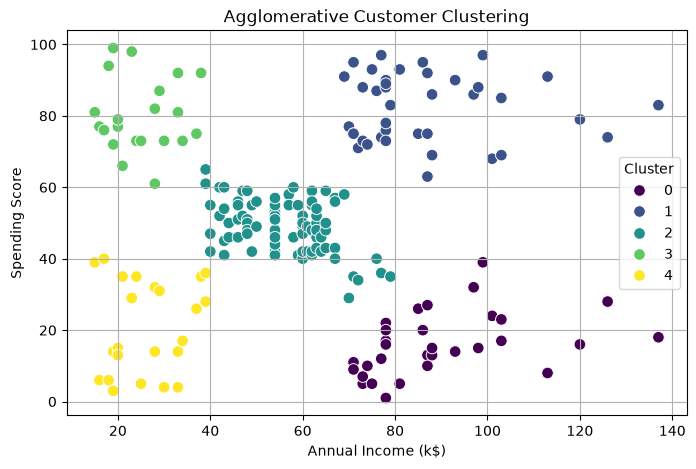


ALGORITHM: DBSCAN
Number of Clusters: 2
Silhouette Score: 0.3875583892728279
Davies-Bouldin Index: 0.7888642629621753


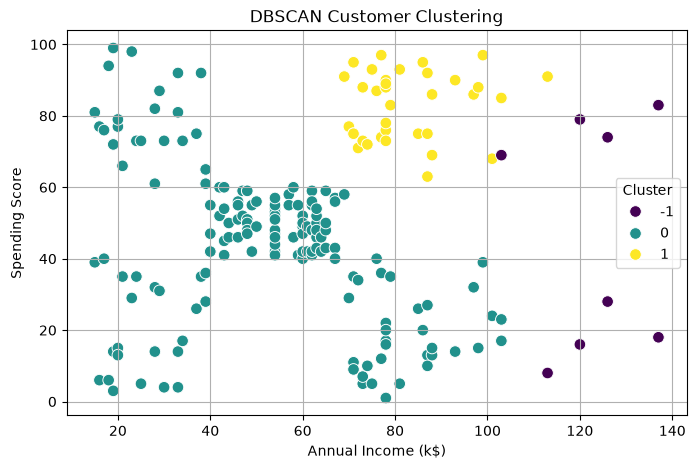


========== CLUSTERING COMPARISON ==========
    Algorithm  Number of Clusters  Silhouette Score  Davies-Bouldin Index
      K-Means                   5            0.5547                0.5722
Agglomerative                   5            0.5538                0.5779
       DBSCAN                   2            0.3876                0.7889

Clustered dataset saved successfully!


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load dataset
data = pd.read_csv("mall_customers.csv")

print("FIRST FIVE ROWS")
print(data.head())

print("\nDATASET SHAPE")
print(data.shape)

print("\nDATASET INFORMATION")
print(data.info())

print("\nMISSING VALUES")
print(data.isnull().sum())

# 2. Select features
X = data[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

# Handle missing values
X = X.fillna(X.median())

# 3. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid()
plt.show()

# 5. Define clustering algorithms
models = {
    "K-Means": KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    ),
    "Agglomerative": AgglomerativeClustering(
        n_clusters=5,
        linkage='ward'
    ),
    "DBSCAN": DBSCAN(
        eps=0.5,
        min_samples=5
    )
}

results = []

# 6. Apply and evaluate clustering algorithms
for name, model in models.items():
    labels = model.fit_predict(X_scaled)
    data[name + " Cluster"] = labels

    # Ignore DBSCAN noise points when counting clusters
    valid_labels = labels[labels != -1]
    n_clusters = len(set(valid_labels))

    # Evaluation
    if name == "DBSCAN":
        mask = labels != -1
        X_eval = X_scaled[mask]
        y_eval = labels[mask]
    else:
        X_eval = X_scaled
        y_eval = labels

    if n_clusters >= 2 and len(y_eval) > n_clusters:
        silhouette = silhouette_score(X_eval, y_eval)
        db_index = davies_bouldin_score(X_eval, y_eval)
    else:
        silhouette = np.nan
        db_index = np.nan

    results.append([
        name,
        n_clusters,
        silhouette,
        db_index
    ])

    print("\n", "=" * 40)
    print("ALGORITHM:", name)
    print("Number of Clusters:", n_clusters)
    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", db_index)

    # 7. Visualize clusters
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        x=X.iloc[:, 0],
        y=X.iloc[:, 1],
        hue=labels,
        palette='viridis',
        s=70
    )

    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score")
    plt.title(name + " Customer Clustering")
    plt.legend(title="Cluster")
    plt.grid()
    plt.show()

# 8. Compare all algorithms
result_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Number of Clusters",
        "Silhouette Score",
        "Davies-Bouldin Index"
    ]
)

print("\n========== CLUSTERING COMPARISON ==========")
print(result_df.round(4).to_string(index=False))

# 9. Save results
data.to_csv("mall_customer_Clustered.csv", index=False)

print("\nClustered dataset saved successfully!")


In [4]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.549 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [6]:
!pip install seaborn

mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Requirement pandas already satisfied.
Requirement matplotlib already satisfied.


In [8]:
!mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.564 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.29.0      pyh5ded981_0         conda-forge
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn        1.9.1       np23py313hde19dca_0  emscripten-forge-4x
+ setuptools          84.2.1      pyhe730653_0         conda-forge
+ threadpoolctl       3.8